# ReMix

Предположим, у нас есть прибор, он работает в двух режимах. Центры и ширина пиков известны. Проверим, восстановят ли четыре оценщика долю правого режима по заданной целевой плотности.

In [1]:
%pip install -q remix-vi==1.0.0 matplotlib

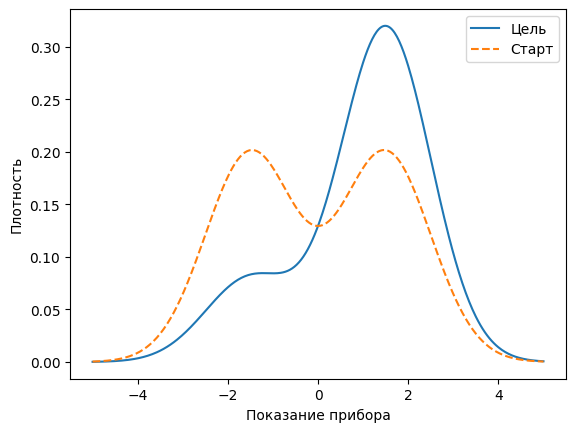

In [2]:
import matplotlib.pyplot as plt
import torch
from torch.distributions import Normal
from remix import ELBOObjective, Implicit, Mixture, PostStratified, ScoreFunction, Stratified

torch.set_default_dtype(torch.float64)
components = [Normal(-1.5, 1.), Normal(1.5, 1.)]
truth = 0.8
target = Mixture(torch.tensor([1 - truth, truth]).log(), components)
objective = ELBOObjective(target.log_prob)
initial = Mixture(torch.zeros(2), components)
grid = torch.linspace(-5, 5, 401)

def density(q):
    return q.log_prob(grid).exp().detach()

plt.plot(grid, density(target), label="Цель")
plt.plot(grid, density(initial), "--", label="Старт")
plt.xlabel("Показание прибора")
plt.ylabel("Плотность")
plt.legend()
plt.show()

Максимизируем ELBO, здесь равную $-D_{KL}(q\|p)$. На каждом шаге используем 32 точки для оценки цели. Запоминаем вес правой компоненты после обновления.

In [3]:
def fit(estimator):
    torch.manual_seed(23)
    logits = torch.nn.Parameter(torch.zeros(2))
    optimizer = torch.optim.Adam([logits], lr=0.035)
    weights = [0.5]
    for _ in range(100):
        optimizer.zero_grad()
        q = Mixture(logits, components)
        result = estimator.estimate(q, objective)
        result.surrogate_loss.backward()
        optimizer.step()
        weights.append(logits.detach().softmax(0)[1].item())
    return weights

paths = {}

def show(name, estimator):
    paths[name] = fit(estimator)
    print(f"{name}: доля правого режима {paths[name][-1]:.1%} (цель {truth:.0%})")

### ScoreFunction
Сэмплируем из смеси. Выигрыш точки относительно базового уровня умножает градиент логарифма её плотности.

In [4]:
show("ScoreFunction", ScoreFunction(n_samples=32))

ScoreFunction: доля правого режима 79.3% (цель 80%)


### Stratified
Берём по 16 точек из каждого режима. Усредняем внутри режима и дифференцируем взвешенную сумму двух средних.

In [5]:
show("Stratified", Stratified(n_samples=16))

Stratified: доля правого режима 79.3% (цель 80%)


### Implicit
Фиксируем квантиль точки. Изменение функции распределения смеси подсказывает, как сдвинулась бы точка при изменении весов.

In [6]:
show("Implicit", Implicit(n_samples=32))

Implicit: доля правого режима 79.4% (цель 80%)


### PostStratified
Для каждой точки вычисляем вероятности принадлежности режимам. В обновление весов входит вклад каждого возможного режима.

In [7]:
show("PostStratified", PostStratified(n_samples=32))

PostStratified: доля правого режима 79.3% (цель 80%)


### Как менялась доля правого режима?

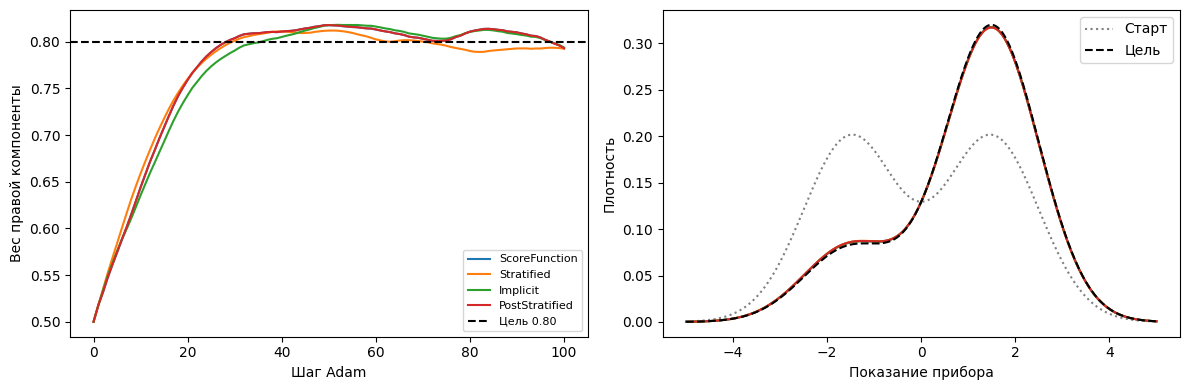

In [8]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(12, 4))
for name, weights in paths.items():
    line, = ax.plot(weights, label=name)
    right = weights[-1]
    fitted = Mixture(torch.tensor([1 - right, right]).log(), components)
    bx.plot(grid, density(fitted), color=line.get_color())
ax.axhline(truth, color="black", ls="--", label="Цель 0.80")
ax.set(xlabel="Шаг Adam", ylabel="Вес правой компоненты")
ax.legend(fontsize=8)
bx.plot(grid, density(initial), ":", color="gray", label="Старт")
bx.plot(grid, density(target), "k--", label="Цель")
bx.set(xlabel="Показание прибора", ylabel="Плотность")
bx.legend()
fig.tight_layout()
plt.show()

## Увидит ли модель редкий режим прибора?
У прибора три режима: обычная работа (63%), повышенная нагрузка (28%) и редкий всплеск (9%). Эталон — смесь распределений Лапласа. Теперь учим веса, центры и ширины сразу трёх компонент. На старте правой компоненте отведено всего 3% массы.

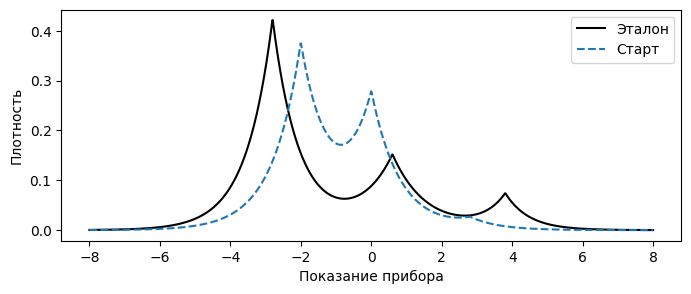

In [9]:
from torch.distributions import Laplace

torch.set_num_threads(1)

def laplace_mixture(logits, centers, scales):
    return Mixture(logits, [Laplace(m, s) for m, s in zip(centers, scales)])

regimes = laplace_mixture(torch.tensor([0.63, 0.28, 0.09]).log(),
                         [-2.8, 0.6, 3.8], [0.75, 0.95, 0.65])
regime_objective = ELBOObjective(regimes.log_prob)

def initial_parameters():
    return [torch.nn.Parameter(x) for x in (
        torch.tensor([0.57, 0.40, 0.03]).log(),
        torch.tensor([-2.0, 0.0, 2.8]),
        torch.zeros(3),
    )]

def model(params):
    logits, centers, raw_scales = params
    scales = 0.6 + 0.4 * raw_scales.sigmoid()
    return laplace_mixture(logits, centers, scales)

dx = 0.01
nodes = (torch.arange(6000) + 0.5) * dx - 30
target_log_density = regimes.log_prob(nodes)

def grid_kl(q):
    log_q = q.log_prob(nodes)
    return dx * (log_q.exp() * (log_q - target_log_density)).sum()

def plot_density(ax, q, **style):
    x = nodes[nodes.abs() < 8]
    ax.plot(x, q.log_prob(x).detach().exp(), **style)

fig, ax = plt.subplots(figsize=(8, 3))
plot_density(ax, regimes, label="Эталон", color="black")
plot_density(ax, model(initial_parameters()), label="Старт", linestyle="--")
ax.set(xlabel="Показание прибора", ylabel="Плотность")
ax.legend()
plt.show()

### В какую сторону сдвигать редкий пик?
При 24 случайных точках вероятность ни разу не выбрать правый режим на старте равна около 48%. Stratified берёт по 8 точек из каждого режима. Сравним 100 оценок производной KL по центру правой компоненты с производной численного интеграла в той же стартовой точке.

ScoreFunction   RMSE = 0.0253
Stratified      RMSE = 0.0252
Implicit        RMSE = 0.0250
PostStratified  RMSE = 0.0250


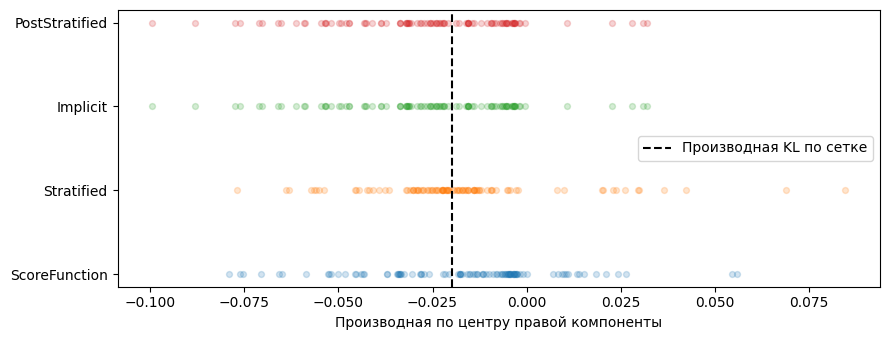

In [10]:
methods = {
    "ScoreFunction": ScoreFunction(n_samples=24),
    "Stratified": Stratified(n_samples=8),
    "Implicit": Implicit(n_samples=24),
    "PostStratified": PostStratified(n_samples=24),
}
params = initial_parameters()
centers = params[1]
reference = torch.autograd.grad(grid_kl(model(params)), centers)[0][-1].item()

fig, ax = plt.subplots(figsize=(9, 3.5))
for row, (name, method) in enumerate(methods.items()):
    torch.manual_seed(71)
    gradients = []
    for _ in range(100):
        loss = method.estimate(model(params), regime_objective).surrogate_loss
        gradients.append(torch.autograd.grad(loss, centers)[0][-1].item())
    values = torch.tensor(gradients)
    rmse = (values - reference).square().mean().sqrt().item()
    ax.scatter(values, [row] * len(values), alpha=0.2, s=18)
    print(f"{name:15} RMSE = {rmse:.4f}")
ax.axvline(reference, color="black", ls="--", label="Производная KL по сетке")
ax.set_yticks(range(len(methods)), labels=list(methods))
ax.set_xlabel("Производная по центру правой компоненты")
ax.legend()
fig.tight_layout()
plt.show()

### Как ошибка градиента отражается на обучении?
У каждого метода одинаковый старт, 150 шагов Adam и 24 точки для оценки цели на шаг.

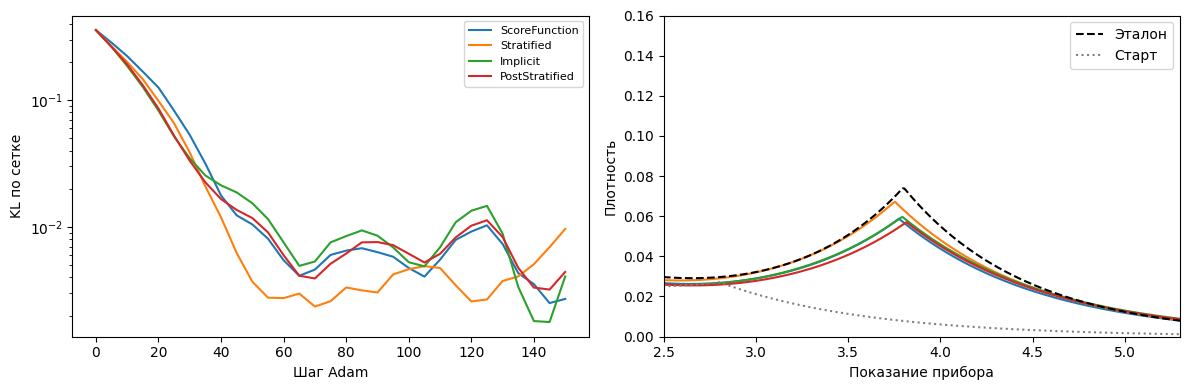

In [11]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(12, 4))
for name, method in methods.items():
    torch.manual_seed(19)
    params = initial_parameters()
    optimizer = torch.optim.Adam(params, lr=0.025)
    steps, errors = [], []
    for step in range(151):
        q = model(params)
        if step % 5 == 0:
            with torch.no_grad():
                steps.append(step)
                errors.append(grid_kl(q).item())
        if step == 150:
            break
        optimizer.zero_grad()
        method.estimate(q, regime_objective).surrogate_loss.backward()
        optimizer.step()
    line, = ax.plot(steps, errors, label=name)
    plot_density(bx, q, color=line.get_color())

plot_density(bx, regimes, color="black", linestyle="--", label="Эталон")
plot_density(bx, model(initial_parameters()), color="gray", linestyle=":", label="Старт")
ax.set(xlabel="Шаг Adam", ylabel="KL по сетке", yscale="log")
bx.set(xlim=(2.5, 5.3), ylim=(0, 0.16), xlabel="Показание прибора", ylabel="Плотность")
ax.legend(fontsize=8)
bx.legend()
fig.tight_layout()
plt.show()